# wPINN: el mejor resultado contra el experimento del paper (choque móvil)

Ley de conservación de Burgers en 2D,
$u_t + \partial_x(u^2/2) + \partial_y(u^2/2) = 0$ en $[-1,1]^2 \times [0, 0.5]$, con $u_0 = 1$ si
$x \le 0$ y $u_0 = 0$ si $x > 0$. La solución es un choque que viaja a velocidad $1/2$: en
$t = T$ está en $x = 0.25$.

1. **Montaje del método**: idéntico a la sección 1 de `wpinn_simple.ipynb`.
2. **Comparación**: el experimento del paper de Abreu, Florindo y Lambert (ECCOMAS 2024) contra la
   mejor configuración que encontramos en los experimentos de `wpinn_simple.ipynb`, todo entrenado
   con el mismo código, una corrida por configuración.

## 1. Montaje del método

Todo lo que se necesita para entrenar: el problema, las redes, los puntos, el residual débil y el bucle min-max. Las secciones siguientes son experimentos que reusan estas piezas.

### 1.1 Librerías y configuración

In [1]:
import copy
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import parameters_to_vector, vector_to_parameters   # pesos <-> un solo vector (para el punto de silla)
import matplotlib.pyplot as plt

# Semilla fija para que dos corridas den lo mismo.
torch.manual_seed(0)
np.random.seed(0)

# GPU si hay, si no CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


### 1.2 El problema: choque móvil

In [2]:
# Dominio: x e y en [-1, 1], tiempo en [0, T].
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
T = 0.5

# Volumen del dominio espacio-temporal |D| = 2 * 2 * 0.5 = 2.
# Sirve para pasar de un promedio Monte Carlo a una integral.
volume = (x_max - x_min) * (y_max - y_min) * T

# Flujo de Burgers. Es el mismo en x y en y.
def flux(u):
    return 0.5 * u**2

# Dato inicial: 1 a la izquierda de x = 0, 0 a la derecha. No depende de y.
def initial_condition(x):
    return torch.where(x <= 0.0, 1.0, 0.0)

# Velocidad del choque (Rankine-Hugoniot): s = (H(1) - H(0)) / (1 - 0) = 1/2.
shock_speed = 0.5

# Solución exacta en numpy, sólo para comparar al final.
def exact_solution(x, t):
    return np.where(x <= shock_speed * t, 1.0, 0.0)

### 1.3 Las dos redes

- $u_\theta(x,y,t)$: la solución. 6 capas ocultas de 20 neuronas (como el paper).
- $\xi_\eta(x,y,t)$: la red de la función test. 4 capas de 10, más pequeña a propósito.

In [3]:
class Sine(nn.Module):
    # Activación seno. PyTorch no la trae como capa, así que la defino aquí.
    # De Ryck et al. la usan en la red u; sirve para uno de los experimentos de arquitectura.
    def forward(self, x):
        return torch.sin(x)


def build_network(n_hidden_layers, width, activation=nn.Tanh):
    # Red totalmente conectada: entra (x, y, t), sale un número.
    # Las dos redes del método son iguales salvo el tamaño, por eso una sola función.
    # activation es la CLASE (nn.Tanh, Sine, ...), no una instancia: se crea una por capa.
    layers = [nn.Linear(3, width), activation()]
    for _ in range(n_hidden_layers - 1):
        layers += [nn.Linear(width, width), activation()]
    layers.append(nn.Linear(width, 1))  # sin activación al final: la salida puede valer cualquier cosa
    return nn.Sequential(*layers).to(device)


# Red de la función test: sale xi. Luego phi = ventana * softplus(xi).
# Una sola para todo el notebook: se reinicia en cada época, así que da igual reusarla.
# (train_wpinn la reconstruye si se le pide otro tamaño.)
test_network = build_network(n_hidden_layers=4, width=10)

# La red solución NO se crea aquí: train_wpinn crea una nueva en cada entrenamiento,
# así cada corrida empieza desde cero.

# No normalizo las entradas: x e y ya están en [-1, 1] y t en [0, 0.5],
# así que las tanh no se saturan.
print(build_network(n_hidden_layers=6, width=20))
print(test_network)

Sequential(
  (0): Linear(in_features=3, out_features=20, bias=True)
  (1): Tanh()
  (2): Linear(in_features=20, out_features=20, bias=True)
  (3): Tanh()
  (4): Linear(in_features=20, out_features=20, bias=True)
  (5): Tanh()
  (6): Linear(in_features=20, out_features=20, bias=True)
  (7): Tanh()
  (8): Linear(in_features=20, out_features=20, bias=True)
  (9): Tanh()
  (10): Linear(in_features=20, out_features=20, bias=True)
  (11): Tanh()
  (12): Linear(in_features=20, out_features=1, bias=True)
)
Sequential(
  (0): Linear(in_features=3, out_features=10, bias=True)
  (1): Tanh()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): Tanh()
  (4): Linear(in_features=10, out_features=10, bias=True)
  (5): Tanh()
  (6): Linear(in_features=10, out_features=10, bias=True)
  (7): Tanh()
  (8): Linear(in_features=10, out_features=1, bias=True)
)


#### Diagrama de las redes

Cada columna es una capa: entrada $(x, y, t)$ en azul, capas ocultas en gris y salida en naranja.
Se dibujan a lo sumo 8 neuronas por capa; el ancho real va escrito debajo de cada columna y la
activación encima. Abajo está la red test: su salida $\xi$ se convierte en
$\varphi = \mathrm{softplus}(\xi)\,(1-x^2)(1-y^2)$.

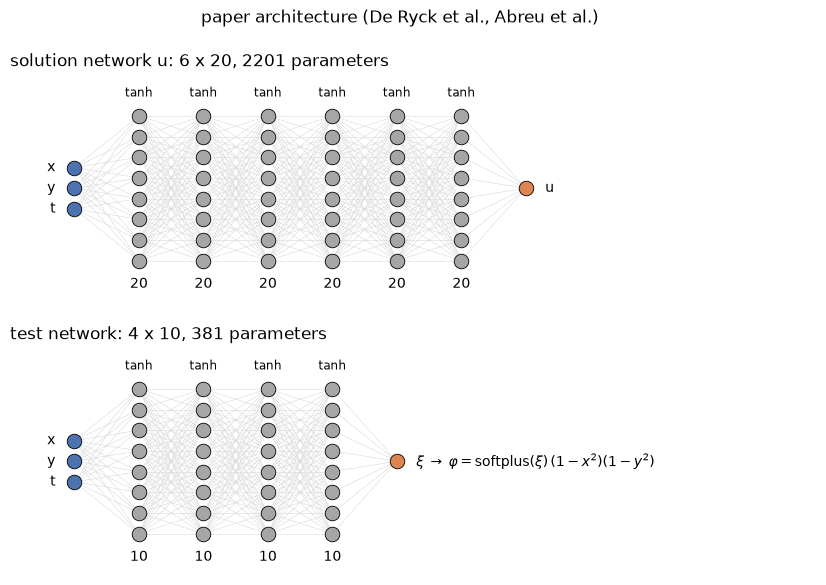

In [4]:
def count_parameters(network):
    # Número de pesos entrenables (matrices + sesgos).
    return sum(parameter.numel() for parameter in network.parameters())


def draw_network_row(ax, n_hidden_layers, width, activation_name, output_label, max_drawn_neurons=8):
    # Dibuja una red en un eje: una columna de círculos por capa.
    layer_sizes = [3] + [width] * n_hidden_layers + [1]
    last_layer = len(layer_sizes) - 1

    # Alturas de los círculos de cada columna, centradas en 0.
    neuron_heights = []
    for size in layer_sizes:
        n_drawn = min(size, max_drawn_neurons)
        neuron_heights.append(np.arange(n_drawn) - (n_drawn - 1) / 2)

    # Conexiones primero (zorder 1) para que queden debajo de los círculos.
    for k in range(last_layer):
        for y_left in neuron_heights[k]:
            for y_right in neuron_heights[k + 1]:
                ax.plot([k, k + 1], [y_left, y_right], color="0.85", linewidth=0.4, zorder=1)

    # Neuronas: el color dice el papel de la capa (entrada, oculta, salida).
    for k, heights in enumerate(neuron_heights):
        if k == 0:
            color = "#4C72B0"     # entrada
        elif k == last_layer:
            color = "#DD8452"     # salida
        else:
            color = "0.65"        # oculta
        ax.scatter(np.full(len(heights), k), heights, s=110, color=color,
                   edgecolor="black", linewidth=0.6, zorder=2)

    # Nombres de las entradas y de la salida.
    # [::-1] para que x quede arriba y t abajo (las alturas van de abajo hacia arriba).
    for y, name in zip(neuron_heights[0][::-1], ["x", "y", "t"]):
        ax.text(-0.3, y, name, ha="right", va="center")
    ax.text(last_layer + 0.3, 0, output_label, ha="left", va="center")

    # Ancho real debajo y activación encima de cada capa oculta.
    half_height = (min(width, max_drawn_neurons) - 1) / 2
    for k in range(1, last_layer):
        ax.text(k, -half_height - 0.8, str(width), ha="center", va="top")
        ax.text(k, half_height + 0.8, activation_name, ha="center", va="bottom", fontsize="small")
    ax.set_ylim(-half_height - 2.0, half_height + 2.0)
    ax.axis("off")


def draw_architecture(title, u_hidden_layers=6, u_width=20, u_activation=nn.Tanh,
                      test_hidden_layers=4, test_width=10):
    # Diagrama de las dos redes de una arquitectura: u arriba, phi abajo.
    # Mismos nombres de argumento que train_wpinn, para poder llamarla con **architectures[name].
    # Los parámetros se cuentan construyendo la red de verdad: así no hay fórmula que se desincronice.
    u_parameters = count_parameters(build_network(u_hidden_layers, u_width, u_activation))
    test_parameters = count_parameters(build_network(test_hidden_layers, test_width))

    n_columns = max(u_hidden_layers, test_hidden_layers) + 2
    fig, axes = plt.subplots(2, 1, figsize=(0.8 * n_columns + 4.0, 6.5))
    draw_network_row(axes[0], u_hidden_layers, u_width, u_activation.__name__.lower(), "u")
    axes[0].set_title(f"solution network u: {u_hidden_layers} x {u_width}, {u_parameters} parameters", loc="left")
    draw_network_row(axes[1], test_hidden_layers, test_width, "tanh",
                     r"$\xi \;\rightarrow\; \varphi = \mathrm{softplus}(\xi)\,(1-x^2)(1-y^2)$")
    axes[1].set_title(f"test network: {test_hidden_layers} x {test_width}, {test_parameters} parameters", loc="left")
    # Mismo eje x en las dos filas, con espacio a la derecha para el texto de la salida.
    for ax in axes:
        ax.set_xlim(-1.0, n_columns + 3.5)
    fig.suptitle(title)
    plt.show()


# La arquitectura del paper, como referencia.
draw_architecture("paper architecture (De Ryck et al., Abreu et al.)")

### 1.4 Puntos de colocación

Se sortean **una sola vez** antes de entrenar:

- interiores: donde se mide el residual débil;
- iniciales ($t = 0$): donde se pide $u = u_0$;
- de frontera en $x = \pm 1$: donde se pide $u = u_0$. Vale porque el choque sólo llega a
  $x = 0.25$ en $t = T$ y nunca toca esas caras;
- pares periódicos en $y = \pm 1$: donde se pide $u(x, -1, t) = u(x, 1, t)$.

**Por qué las caras $y = \pm 1$ no llevan el dato inicial.** El choque es la recta $x = t/2$ para
**todo** $y$, así que atraviesa las caras $y = \pm 1$ y se mueve por ellas. Imponer ahí
$u = u_0(x)$ obliga al choque a quedarse en $x = 0$ en el borde y, como la red es suave en $y$,
en todo el dominio. **Ese error estuvo en la primera versión de este notebook** y explicaba que
todos los experimentos dieran un choque detenido. Como la solución no depende de $y$, la condición
correcta y que no usa la exacta es la periódica.

In [5]:
def sample_interior_points(n_points):
    # Uniformes en la caja [-1, 1] x [-1, 1] x [0, T].
    x = x_min + (x_max - x_min) * torch.rand(n_points, 1)
    y = y_min + (y_max - y_min) * torch.rand(n_points, 1)
    t = T * torch.rand(n_points, 1)
    return torch.cat([x, y, t], dim=1).to(device)


def sample_initial_points(n_points):
    # Igual que los interiores pero con t = 0.
    points = sample_interior_points(n_points)
    points[:, 2] = 0.0
    return points


def sample_face_points(n_points, column, value):
    # Puntos sobre una cara: sorteo en toda la caja y luego "pego" una coordenada a la cara.
    points = sample_interior_points(n_points)
    points[:, column] = value
    return points


n_interior = 16000
n_initial = 2000
n_boundary = 2000   # la mitad en x = -1 y la mitad en x = 1
n_periodic = 1000   # pares (y = -1, y = 1)

interior_points = sample_interior_points(n_interior)
# requires_grad para poder derivar u y phi respecto a (x, y, t).
interior_points.requires_grad_(True)
# Copia de los puntos uniformes y sus pesos de importancia (todos 1 = muestreo uniforme).
# El experimento 5 cambia estos dos globales; train_wpinn los restaura cuando no se pide otro muestreo.
uniform_interior_points = interior_points
interior_weights = torch.ones(n_interior, 1, device=device)

initial_points = sample_initial_points(n_initial)
initial_values = initial_condition(initial_points[:, 0:1])

# Caras x = -1 y x = 1: Dirichlet con el dato inicial. El choque (x = t/2 <= 0.25) nunca llega aquí.
left_face_points = sample_face_points(n_boundary // 2, column=0, value=x_min)
right_face_points = sample_face_points(n_boundary // 2, column=0, value=x_max)
boundary_points = torch.cat([left_face_points, right_face_points], dim=0)
boundary_values = initial_condition(boundary_points[:, 0:1])

# Caras y = -1 e y = 1: periódica. Los dos puntos de cada par comparten x y t.
# NO se usa el dato inicial aquí: el choque atraviesa estas caras y se mueve con el tiempo.
periodic_bottom_points = sample_face_points(n_periodic, column=1, value=y_min)
periodic_top_points = periodic_bottom_points.clone()
periodic_top_points[:, 1] = y_max


def data_losses(u_network):
    # Pérdidas de datos: (inicial, frontera). La de frontera suma Dirichlet en x y periódica en y.
    initial_loss = ((u_network(initial_points) - initial_values) ** 2).mean()
    dirichlet_loss = ((u_network(boundary_points) - boundary_values) ** 2).mean()
    periodic_loss = ((u_network(periodic_bottom_points) - u_network(periodic_top_points)) ** 2).mean()
    return initial_loss, dirichlet_loss + periodic_loss


print(interior_points.shape, initial_points.shape, boundary_points.shape, periodic_bottom_points.shape)

torch.Size([16000, 3]) torch.Size([2000, 3]) torch.Size([2000, 3]) torch.Size([1000, 3])


### 1.5 Constantes de Kruzhkov

La desigualdad debe valer para **toda** $c$. Uso 9 valores entre $-0.25$ y $1.25$: el rango
de $u$ es $[0, 1]$ y me salgo un 25 % por cada lado. Con $c$ fuera del rango de $u$ la
desigualdad se vuelve la ecuación misma (con un signo o el otro), así que los extremos
imponen la EDP y los del medio imponen la entropía.

In [6]:
# Forma (1, 9) para que u - c, con u de forma (N, 1), dé (N, 9): una columna por c.
c = torch.linspace(-0.25, 1.25, 9, device=device).reshape(1, -1)
print(c)

tensor([[-0.2500, -0.0625,  0.1250,  0.3125,  0.5000,  0.6875,  0.8750,  1.0625,
          1.2500]], device='cuda:0')


### 1.6 Función test y residual débil

$\varphi = (1 - x^2)(1 - y^2)\cdot \mathrm{softplus}(\xi)$:

- `softplus` la hace positiva, que es lo que pide Kruzhkov;
- la ventana $(1-x^2)(1-y^2)$ la anula en el borde, así que al integrar por partes en
  $x$ e $y$ no quedan términos de frontera.

El residual se normaliza por $\|\nabla_x \varphi\|^2$; si no, la adversaria podría hacerlo
crecer sólo multiplicando $\varphi$ por un número grande.

**Las tres pérdidas del paper** se diferencian sólo en qué se suma dentro de la integral
(con $s = \mathrm{sign}(u-c)$):

| Pérdida | Integrando | Qué añade |
|---|---|---|
| L0 (ec. 10) | $\varphi\, s\, u_t - Q\,(\varphi_x + \varphi_y)$ | la desigualdad de Kruzhkov |
| L1 (ec. 11, corregida) | L0 $+\; s\, u_t$ + flujo de entropía por el borde | la tasa de entropía total, sin $\varphi$ |
| L2 (ec. 12) | L1 $+\; \epsilon\, s\,(u_x \varphi_x + u_y \varphi_y)$ | difusión débil $\epsilon \Delta u$, con $\epsilon = 10^{-3}$ |

Por eso `weak_residual` recibe `level` (0, 1 o 2) y el gradiente completo de $u$: L2 necesita
$u_x$ y $u_y$, no sólo $u_t$.

Los interruptores `positive`, `window` (en `test_function`) y `normalize` (en `weak_residual`)
existen para los casos borde del final. Por defecto valen `True` y reproducen el paper.

**Corrección de L1 respecto al paper.** La ecuación 11 pide que la entropía total
$\int_\Omega |u - c|$ no crezca. Pero en un dominio acotado esa entropía también cambia por lo que
**entra y sale por el borde**: la condición correcta es

$$\frac{d}{dt}\int_\Omega |u - c|\,dx\,dy + \oint_{\partial\Omega} Q(u, c)\cdot n\,ds \;\le\; 0 .$$

Sin el término de borde, el choque que avanza (que agranda la zona donde $u = 1$) parece "crear"
entropía para $c < 1/2$ y la pérdida lo castiga: el mínimo pasa a ser un choque quieto. **La
primera versión de este notebook implementaba la ecuación 11 tal como está escrita** y por eso L1
y L2 dejaban el choque en $x = 0$. Aquí `boundary_entropy_flux` agrega el término de borde: con
$y$ periódica lo que sale por $y = 1$ entra por $y = -1$, así que sólo cuentan las caras
$x = \pm 1$. Con `entropy_boundary_flux=False` en `train_wpinn` se reproduce la ecuación 11
original.


In [7]:
def test_function(points, positive=True, window=True):
    # Devuelve phi y sus derivadas en x y en y.
    # positive y window son interruptores para los casos borde; con True reproducen el paper.
    phi = test_network(points)
    if positive:
        # softplus > 0: Kruzhkov es una desigualdad probada contra phi >= 0.
        phi = F.softplus(phi)
    if window:
        # La ventana anula phi en el borde: así al integrar por partes no quedan términos de frontera.
        x = points[:, 0:1]
        y = points[:, 1:2]
        phi = (1 - x**2) * (1 - y**2) * phi
    # create_graph=True porque luego se hace backward a través de phi_x y phi_y.
    gradient = torch.autograd.grad(phi.sum(), points, create_graph=True)[0]
    phi_x = gradient[:, 0:1]
    phi_y = gradient[:, 1:2]
    return phi, phi_x, phi_y


def weak_residual(u, u_gradient, phi, phi_x, phi_y, level, epsilon=1e-3, normalize=True, weights=None,
                  boundary_flux=None):
    # R(c) para las 9 constantes a la vez, y la norma de grad phi.
    # level = 0, 1 o 2 elige la pérdida L0, L1 o L2 del paper.
    u_x = u_gradient[:, 0:1]
    u_y = u_gradient[:, 1:2]
    u_t = u_gradient[:, 2:3]

    sign = torch.sign(u - c)                    # (N, 9)
    Q = sign * (flux(u) - flux(c))              # flujo de entropía, (N, 9)

    # L0: Kruzhkov. Como el flujo es el mismo en x y en y: Q phi_x + Q phi_y = Q (phi_x + phi_y).
    integrand = phi * sign * u_t - Q * (phi_x + phi_y)
    # L1: + tasa de entropía total (sin phi).
    if level >= 1:
        integrand = integrand + sign * u_t
    # L2: + difusión débil (-eps Lap u integrado por partes contra phi).
    if level >= 2:
        integrand = integrand + epsilon * sign * (u_x * phi_x + u_y * phi_y)

    # Pesos de importancia: con puntos no uniformes cada punto pesa w = (1/|D|) / p(punto),
    # así la media sigue siendo un estimador correcto de la integral. Sin pesos, w = 1 (uniforme).
    if weights is None:
        weights = torch.ones_like(u)
    R = volume * (integrand * weights).mean(dim=0)          # (9,), una integral por cada c
    # L1 y L2: + entropía que sale por el borde (calculada aparte, ver boundary_entropy_flux).
    if level >= 1 and boundary_flux is not None:
        R = R + boundary_flux
    if normalize:
        norm = volume * ((phi_x**2 + phi_y**2) * weights).mean()
    else:
        # Caso borde: sin normalizar. Dividir por 1 deja todo lo demás igual.
        norm = torch.tensor(1.0, device=device)
    return R, norm


def boundary_entropy_flux(u_network):
    # Integral de Q(u, c) . n sobre el borde y en [0, T], para las 9 constantes a la vez: (9,).
    # Con y periódica, lo que sale por y = 1 entra por y = -1 y se cancela: sólo cuentan x = -1 y x = 1.
    # En x = 1 la normal es +x (sale) y en x = -1 es -x (entra).
    face_area = (y_max - y_min) * T            # cada cara es un rectángulo de y por t
    u_left = u_network(left_face_points)
    u_right = u_network(right_face_points)
    Q_left = torch.sign(u_left - c) * (flux(u_left) - flux(c))
    Q_right = torch.sign(u_right - c) * (flux(u_right) - flux(c))
    return face_area * (Q_right.mean(dim=0) - Q_left.mean(dim=0))

### 1.7 Entrenamiento min-max

En cada época:

1. **Reinicio** la red test (algoritmo de De Ryck): el máximo viejo ya no sirve porque $u$ cambió.
2. **Ascenso**: 5 pasos que suben el residual moviendo $\varphi$, con $u$ congelada (`detach`).
   Aquí uso $R|R|$ en vez de $\mathrm{ReLU}(R)^2$, porque ReLU da gradiente cero mientras no haya
   violación y la adversaria nunca arrancaría.
3. **Descenso**: 1 paso que baja la pérdida total moviendo $u$, con $\varphi$ congelada.

Pérdida total: $\max_c \frac{\mathrm{ReLU}(R(c))^2}{\|\nabla\varphi\|^2} + \lambda\,(\text{inicial} + \text{frontera})$ con $\lambda = 10$.

In [8]:
def reset_test_network():
    # Nuevos pesos aleatorios para la red test (algoritmo de De Ryck).
    for layer in test_network:
        if isinstance(layer, nn.Linear):
            layer.reset_parameters()
    # Optimizador nuevo también: sus momentos eran de los pesos viejos.
    return torch.optim.Adam(test_network.parameters(), lr=1e-2)


def adversary_ascent(u_network, test_optimizer, n_steps, level, positive=True, window=True, normalize=True,
                     entropy_boundary_flux=True):
    # Sube el residual moviendo phi, con u congelada. Devuelve el objetivo alcanzado.
    u = u_network(interior_points)
    u_gradient = torch.autograd.grad(u.sum(), interior_points)[0]   # columnas: u_x, u_y, u_t
    # detach: u no cambia durante el ascenso, así que no debe recibir gradiente.
    u = u.detach()
    u_gradient = u_gradient.detach()
    # Flujo de entropía por el borde (sólo L1 y L2), también con u congelada.
    boundary_flux = None
    if level >= 1 and entropy_boundary_flux:
        boundary_flux = boundary_entropy_flux(u_network).detach()

    for step in range(n_steps):
        test_optimizer.zero_grad()
        phi, phi_x, phi_y = test_function(interior_points, positive, window)
        R, norm = weak_residual(u, u_gradient, phi, phi_x, phi_y, level, normalize=normalize,
                                weights=interior_weights, boundary_flux=boundary_flux)
        adversary_objective = (R * R.abs() / norm).max()
        # Para maximizar, minimizo el negativo.
        (-adversary_objective).backward()
        test_optimizer.step()

    return max(adversary_objective.item(), 0.0)


def solution_descent(u_network, u_optimizer, data_weight, level, positive=True, window=True, normalize=True,
                     entropy_boundary_flux=True):
    # Baja la pérdida total moviendo u, con phi congelada. Devuelve las pérdidas.
    phi, phi_x, phi_y = test_function(interior_points, positive, window)
    phi = phi.detach()
    phi_x = phi_x.detach()
    phi_y = phi_y.detach()

    u_optimizer.zero_grad()
    u = u_network(interior_points)
    # Aquí sí create_graph=True: la pérdida depende de las derivadas de u y quiero su gradiente en theta.
    u_gradient = torch.autograd.grad(u.sum(), interior_points, create_graph=True)[0]
    boundary_flux = None
    if level >= 1 and entropy_boundary_flux:
        boundary_flux = boundary_entropy_flux(u_network)
    R, norm = weak_residual(u, u_gradient, phi, phi_x, phi_y, level, normalize=normalize,
                                weights=interior_weights, boundary_flux=boundary_flux)
    weak_loss = (torch.relu(R) ** 2 / norm).max()

    initial_loss, boundary_loss = data_losses(u_network)

    total_loss = weak_loss + data_weight * (initial_loss + boundary_loss)
    total_loss.backward()
    u_optimizer.step()

    return {
        "total": total_loss.item(),
        "weak": weak_loss.item(),
        "initial": initial_loss.item(),
        "boundary": boundary_loss.item(),
    }


def train_wpinn(level, n_epochs=1000, n_adversary_steps=5, data_weight=10.0,
                positive=True, window=True, normalize=True, label=None, seed=0,
                u_hidden_layers=6, u_width=20, u_activation=nn.Tanh,
                test_hidden_layers=4, test_width=10, sampler=None, resample_every=None,
                entropy_boundary_flux=True):
    # Entrena una red solución nueva con la pérdida L0, L1 o L2. Devuelve la red y su historia.
    # positive, window y normalize son los interruptores de los casos borde; con True es el paper.
    # Los argumentos u_* y test_* eligen la arquitectura; por defecto es la del paper.
    # sampler elige los puntos interiores (experimento 5); None = uniformes, como en el paper.
    # entropy_boundary_flux=False reproduce la ecuación 11 del paper tal como está escrita (sin borde).
    # Las funciones de entrenamiento usan la red test, los puntos y los pesos globales.
    global test_network, interior_points, interior_weights
    if label is None:
        label = f"L{level}"

    # Misma semilla, mismos pesos iniciales: la comparación entre corridas es justa.
    torch.manual_seed(seed)
    u_network = build_network(u_hidden_layers, u_width, u_activation)
    # La red test se reconstruye con el tamaño pedido (sus pesos se sortean igual en cada época).
    test_network = build_network(test_hidden_layers, test_width)
    u_optimizer = torch.optim.Adam(u_network.parameters(), lr=1e-3)

    # Puntos interiores: los uniformes de siempre, o los que dé el muestreador.
    if sampler is None:
        interior_points = uniform_interior_points
        interior_weights = torch.ones(n_interior, 1, device=device)
    else:
        interior_points, interior_weights = sampler(u_network)

    history = {"total": [], "weak": [], "adversary": [], "initial": [], "boundary": []}
    # Pesos de u cada 10 épocas, aplanados en un vector. Sirven para dibujar la trayectoria
    # del entrenamiento sobre el punto de silla. El primero son los pesos iniciales.
    history["u_parameters"] = [parameters_to_vector(u_network.parameters()).detach().cpu().clone()]
    start = time.time()

    for epoch in range(1, n_epochs + 1):
        # 0. (sólo muestreo adaptativo) re-sortear los puntos con la u actual
        if sampler is not None and resample_every is not None and epoch % resample_every == 0:
            interior_points, interior_weights = sampler(u_network)
        # 1. reinicio
        test_optimizer = reset_test_network()
        # 2. max sobre phi
        adversary_objective = adversary_ascent(u_network, test_optimizer, n_adversary_steps, level,
                                               positive, window, normalize, entropy_boundary_flux)
        # 3. min sobre u
        losses = solution_descent(u_network, u_optimizer, data_weight, level,
                                  positive, window, normalize, entropy_boundary_flux)

        # --- registro --------------------------------------------------------
        history["adversary"].append(adversary_objective)
        for name, value in losses.items():
            history[name].append(value)
        if epoch % 10 == 0:
            history["u_parameters"].append(parameters_to_vector(u_network.parameters()).detach().cpu().clone())

        if epoch % 100 == 0:
            print(f"{label}  epoch {epoch:5d}  total {losses['total']:.3e}  weak {losses['weak']:.3e}  "
                  f"adversary {adversary_objective:.3e}  initial {losses['initial']:.3e}  "
                  f"boundary {losses['boundary']:.3e}  [{time.time() - start:.0f} s]")

    history["seconds"] = time.time() - start
    # Los puntos con que terminó el entrenamiento, para la figura de concentración.
    history["interior_points"] = interior_points.detach().cpu()
    history["test_parameters"] = count_parameters(test_network)
    return u_network, history

### 1.8 Utilidades de evaluación

In [9]:
# Hoja de estilo del proyecto (la misma de los otros notebooks).
plt.style.use("notebook.mplstyle")


def evaluate(network, x, y, t):
    # Evalúa la red en arreglos numpy x, y, t de la misma forma y devuelve u con esa forma.
    points = np.stack([x.ravel(), y.ravel(), t.ravel()], axis=1)
    # numpy da float64 y la red es float32: hay que convertir.
    points = torch.tensor(points, dtype=torch.float32, device=device)
    with torch.no_grad():   # sólo evaluar, no hace falta grafo
        u = network(points).cpu().numpy()
    return u.reshape(x.shape)


# Malla regular de 200 x 200 que usan todas las figuras.
x_axis = np.linspace(x_min, x_max, 200)
y_axis = np.linspace(y_min, y_max, 200)
X, Y = np.meshgrid(x_axis, y_axis)          # forma (n_y, n_x), la que pide pcolormesh

In [10]:
def relative_errors(network):
    # Errores relativos L1 y L2 en t = T sobre la malla de las figuras.
    u_exact = exact_solution(X, T)
    error = np.abs(evaluate(network, X, Y, np.full_like(X, T)) - u_exact)
    relative_l1 = error.sum() / np.abs(u_exact).sum()
    relative_l2 = np.sqrt((error**2).sum()) / np.sqrt((u_exact**2).sum())
    return relative_l1, relative_l2


# Malla fina en x para ubicar el choque con precisión de 0.001.
fine_x_axis = np.linspace(x_min, x_max, 2000)


def shock_position(network, time_value):
    # Posición del choque en y = 0: primer x donde u baja de 0.5 (la mitad del salto de 1 a 0).
    u_cut = evaluate(network, fine_x_axis, np.zeros_like(fine_x_axis), np.full_like(fine_x_axis, time_value))
    below = np.flatnonzero(u_cut < 0.5)
    # Sin choque que ubicar: la red nunca baja de 0.5, o ya empieza por debajo en el borde
    # izquierdo, donde debería valer 1.
    if len(below) == 0 or below[0] == 0:
        return np.nan
    return fine_x_axis[below[0]]

## 2. El mejor resultado contra el experimento del paper

### 2.1 Qué dicen los experimentos

Error relativo $L^1$ en $t = T$ medido en `wpinn_simple.ipynb`, ya con la frontera y L1
corregidas:

| Experimento | Resultado | Decisión |
|---|---|---|
| 1. Pérdidas | L0 0.051, L1 0.036, L2 0.035 | L1 y L2 corregidas mejoran a L0 |
| 3. Casos borde | sin normalización 0.043, sin positividad 0.136, libre 0.254, sin ventana 0.696 | se mantienen las restricciones del paper |
| 4. Arquitectura de $u$ (L0, 3 semillas) | **deep 10 × 20: 0.014 ± 0.002**; paper 0.047 ± 0.014; large 0.054; wide 0.100; tiny 0.347 | **deep**: tres veces menos error que la del paper |
| 4. Tamaño de $\varphi$ | 26 parámetros 0.047, 381 parámetros 0.047, 5121 parámetros 0.046 | no importa: se deja la del paper, 4 × 10 |
| 5. Muestreo | uniforme 0.047; Sobol 0.053; banda con pesos 0.053; RAD 0.109; banda sin pesos 0.165 | **uniforme** |

**Por qué hay dos candidatas.** La arquitectura deep se midió con L0, y la mejora de L2 corregida
se midió con la red del paper; la combinación de las dos no se probó. Por eso se entrenan
**deep + L0** y **deep + L2 corregida**, y se presenta la de menor error.

**El experimento del paper:** L2 con la ecuación 11 **tal como está escrita** (sin flujo de
entropía por el borde), $u$ 6 × 20, $\varphi$ 4 × 10, 16 000 puntos, 1000 épocas,
$\epsilon = 10^{-3}$. El paper no dice qué $\lambda$ usó; se toma $\lambda = 10$, el de De Ryck et al.
Se entrena además **paper, corrected** (la misma red con L2 corregida) para separar cuánto aporta
la corrección de L1 y cuánto la arquitectura.

El paper no reporta errores numéricos para este caso, sólo la figura 3 (cualitativa); por eso su
experimento se reproduce con este mismo código.

### 2.2 Configuraciones

In [11]:
# Arquitectura deep: u de 10 capas de 20. La red test queda como en el paper (4 x 10).
deep_architecture = dict(u_hidden_layers=10, u_width=20)

# Configuración: nombre -> argumentos de train_wpinn. Lo que no se escribe es lo del paper
# (u 6 x 20, phi 4 x 10, lambda = 10, 1000 épocas, puntos uniformes).
configurations = {
    "paper (eq. 11 as written)": dict(level=2, entropy_boundary_flux=False),
    "paper, corrected": dict(level=2),
    "deep + L0": dict(level=0, **deep_architecture),
    "deep + L2 corrected": dict(level=2, **deep_architecture),
}
paper_name = "paper (eq. 11 as written)"
results = {}   # nombre -> (red, historia)


def run_configuration(name):
    # Una sola corrida, con semilla 0, para cada configuración.
    results[name] = train_wpinn(seed=0, label=name, **configurations[name])

#### Arquitectura del paper

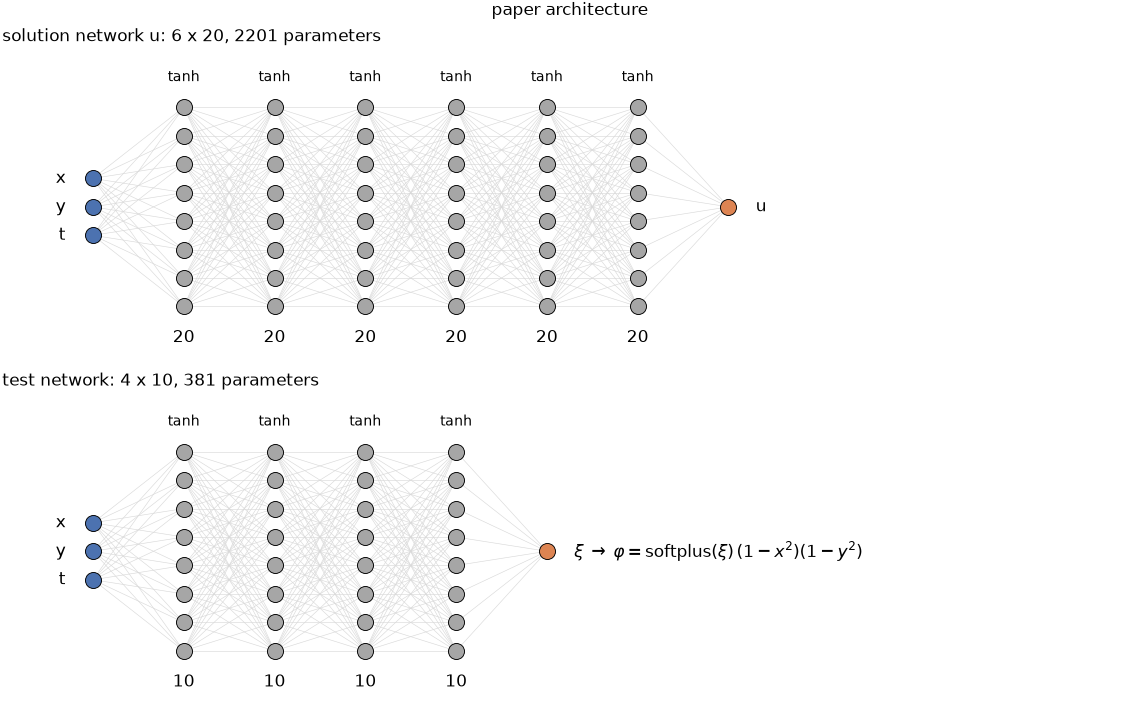

In [12]:
draw_architecture("paper architecture")

#### Arquitectura deep

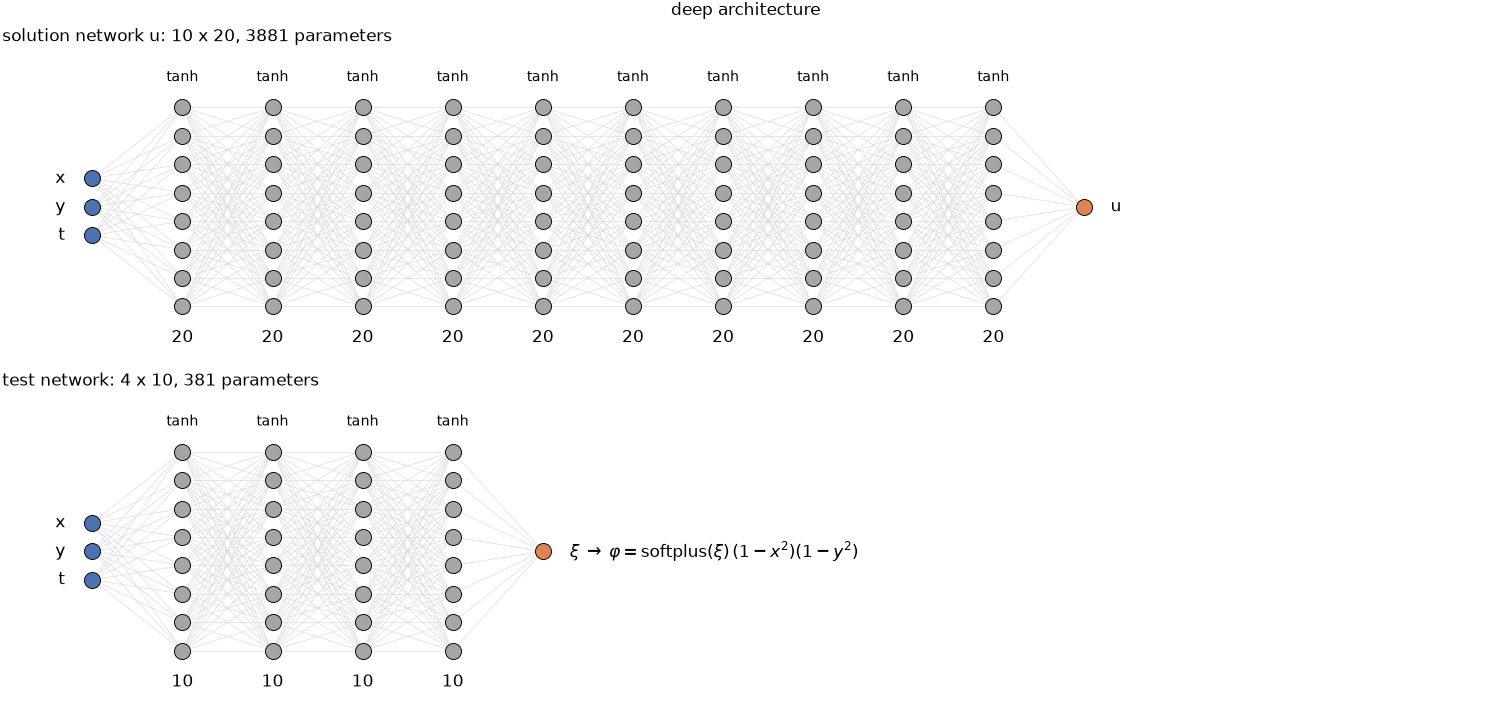

In [13]:
draw_architecture("deep architecture", **deep_architecture)

### 2.3 Entrenamientos

Una corrida por configuración, unos 2 minutos en total.

#### paper (eq. 11 as written)

In [14]:
run_configuration("paper (eq. 11 as written)")

paper (eq. 11 as written)  epoch   100  total 6.311e-01  weak 3.893e-03  adversary 2.931e-03  initial 5.916e-02  boundary 3.552e-03  [3 s]
paper (eq. 11 as written)  epoch   200  total 4.404e-01  weak 7.831e-03  adversary 6.512e-03  initial 4.084e-02  boundary 2.421e-03  [5 s]
paper (eq. 11 as written)  epoch   300  total 1.542e-01  weak 7.655e-03  adversary 6.520e-03  initial 1.452e-02  boundary 1.334e-04  [8 s]
paper (eq. 11 as written)  epoch   400  total 9.541e-02  weak 5.975e-03  adversary 3.895e-03  initial 8.828e-03  boundary 1.158e-04  [10 s]
paper (eq. 11 as written)  epoch   500  total 6.805e-02  weak 7.237e-03  adversary 6.060e-03  initial 6.033e-03  boundary 4.838e-05  [13 s]
paper (eq. 11 as written)  epoch   600  total 4.961e-02  weak 4.857e-03  adversary 3.969e-03  initial 4.438e-03  boundary 3.804e-05  [15 s]
paper (eq. 11 as written)  epoch   700  total 4.148e-02  weak 5.897e-03  adversary 4.937e-03  initial 3.528e-03  boundary 3.074e-05  [18 s]
paper (eq. 11 as writte

#### paper, corrected

In [15]:
run_configuration("paper, corrected")

paper, corrected  epoch   100  total 6.251e-01  weak 6.050e-04  adversary 5.047e-04  initial 5.829e-02  boundary 4.161e-03  [3 s]
paper, corrected  epoch   200  total 4.342e-01  weak 1.002e-03  adversary 8.934e-04  initial 4.090e-02  boundary 2.419e-03  [5 s]
paper, corrected  epoch   300  total 1.396e-01  weak 1.475e-03  adversary 1.442e-03  initial 1.358e-02  boundary 2.279e-04  [8 s]
paper, corrected  epoch   400  total 8.452e-02  weak 1.498e-03  adversary 1.295e-03  initial 8.089e-03  boundary 2.131e-04  [11 s]
paper, corrected  epoch   500  total 5.530e-02  weak 1.528e-03  adversary 1.428e-03  initial 5.268e-03  boundary 1.097e-04  [14 s]
paper, corrected  epoch   600  total 3.929e-02  weak 8.732e-04  adversary 8.405e-04  initial 3.761e-03  boundary 8.110e-05  [16 s]
paper, corrected  epoch   700  total 3.066e-02  weak 4.627e-04  adversary 4.542e-04  initial 2.942e-03  boundary 7.764e-05  [19 s]
paper, corrected  epoch   800  total 2.664e-02  weak 1.928e-03  adversary 1.446e-03  i

#### deep + L0

In [16]:
run_configuration("deep + L0")

deep + L0  epoch   100  total 2.988e-01  weak 2.075e-02  adversary 2.052e-02  initial 2.644e-02  boundary 1.364e-03  [3 s]
deep + L0  epoch   200  total 7.361e-02  weak 3.294e-03  adversary 3.269e-03  initial 6.945e-03  boundary 8.729e-05  [5 s]
deep + L0  epoch   300  total 3.591e-02  weak 7.481e-04  adversary 7.368e-04  initial 3.467e-03  boundary 4.963e-05  [8 s]
deep + L0  epoch   400  total 2.238e-02  weak 3.164e-04  adversary 3.101e-04  initial 2.168e-03  boundary 3.914e-05  [11 s]
deep + L0  epoch   500  total 1.450e-02  weak 1.138e-04  adversary 1.123e-04  initial 1.413e-03  boundary 2.503e-05  [13 s]
deep + L0  epoch   600  total 9.825e-03  weak 1.140e-04  adversary 1.110e-04  initial 9.535e-04  boundary 1.760e-05  [16 s]
deep + L0  epoch   700  total 7.011e-03  weak 1.271e-04  adversary 1.236e-04  initial 6.751e-04  boundary 1.325e-05  [19 s]
deep + L0  epoch   800  total 5.298e-03  weak 1.356e-04  adversary 1.318e-04  initial 4.959e-04  boundary 2.029e-05  [21 s]
deep + L0  

#### deep + L2 corrected

In [17]:
run_configuration("deep + L2 corrected")

deep + L2 corrected  epoch   100  total 2.950e-01  weak 7.744e-04  adversary 7.011e-04  initial 2.798e-02  boundary 1.451e-03  [3 s]
deep + L2 corrected  epoch   200  total 6.993e-02  weak 3.332e-04  adversary 3.210e-04  initial 6.853e-03  boundary 1.068e-04  [7 s]
deep + L2 corrected  epoch   300  total 3.543e-02  weak 2.094e-04  adversary 2.046e-04  initial 3.459e-03  boundary 6.336e-05  [10 s]
deep + L2 corrected  epoch   400  total 2.189e-02  weak 1.572e-04  adversary 1.439e-04  initial 2.125e-03  boundary 4.875e-05  [13 s]
deep + L2 corrected  epoch   500  total 1.433e-02  weak 2.464e-04  adversary 2.377e-04  initial 1.375e-03  boundary 3.335e-05  [17 s]
deep + L2 corrected  epoch   600  total 1.030e-02  weak 5.763e-04  adversary 5.630e-04  initial 9.342e-04  boundary 3.776e-05  [20 s]
deep + L2 corrected  epoch   700  total 8.253e-03  weak 3.116e-04  adversary 2.756e-04  initial 6.455e-04  boundary 1.487e-04  [23 s]
deep + L2 corrected  epoch   800  total 5.581e-03  weak 1.917e-0

### 2.4 Resultados

Errores relativos en $t = T$, posición del choque en $t = T$ (la exacta es $x = 0.25$) y tiempo de
entrenamiento. La mejor configuración se elige sola entre las dos candidatas deep.

In [18]:
summary = {}
for name, (network, history) in results.items():
    relative_l1, relative_l2 = relative_errors(network)
    summary[name] = {"l1": relative_l1, "l2": relative_l2,
                     "shock": shock_position(network, T), "seconds": history["seconds"]}

print(f"{'configuration':28s} {'rel. L1':>8s} {'rel. L2':>8s} {'shock at T (exact 0.25)':>24s} {'seconds':>8s}")
for name, row in summary.items():
    print(f"{name:28s} {row['l1']:8.4f} {row['l2']:8.4f} {row['shock']:24.3f} {row['seconds']:8.0f}")

best_name = min(["deep + L0", "deep + L2 corrected"], key=lambda name: summary[name]["l1"])
best = summary[best_name]
paper = summary[paper_name]
print(f"\nbest configuration: {best_name}")
print(f"relative L1 error: {paper['l1']:.4f} (paper, as written) -> {best['l1']:.4f} (best), "
      f"{paper['l1'] / best['l1']:.1f} times smaller")
print(f"shock position at T: {paper['shock']:.3f} (paper) and {best['shock']:.3f} (best); exact 0.250")

configuration                 rel. L1  rel. L2  shock at T (exact 0.25)  seconds
paper (eq. 11 as written)      0.1735   0.3860                    0.048       25
paper, corrected               0.0353   0.0955                    0.232       27
deep + L0                      0.0122   0.0924                    0.263       27
deep + L2 corrected            0.0115   0.0869                    0.262       33

best configuration: deep + L2 corrected
relative L1 error: 0.1735 (paper, as written) -> 0.0115 (best), 15.1 times smaller
shock position at T: 0.048 (paper) and 0.262 (best); exact 0.250


### 2.5 Comparación

#### Figura 1: solución en t = T

**Figura 1.** Superficie $u(x, y, T)$ de la exacta, del experimento del paper (ecuación 11 tal
como está escrita) y de la mejor configuración, con la misma vista y la misma escala de color,
comparable con la fila "Moving Shock" de la figura 3 del paper. El paper usa el colormap `jet`;
aquí se usa `viridis`, porque `jet` crea bandas que no están en los datos. El salto debe estar en
$x = 0.25$.

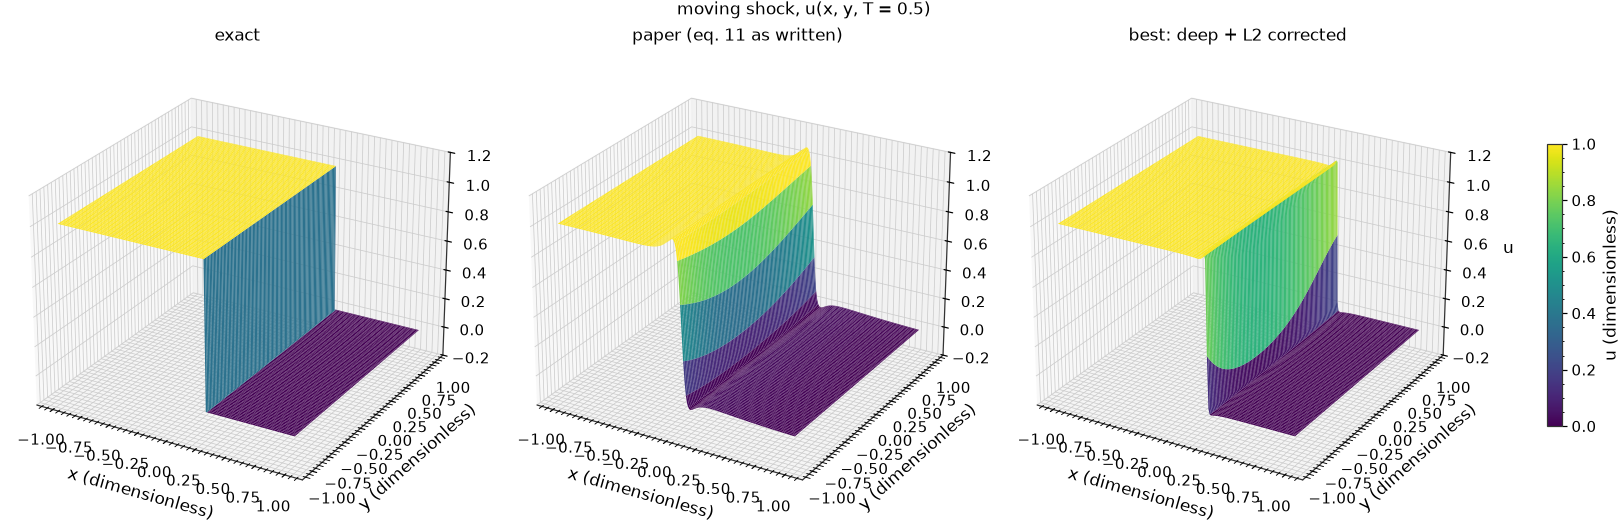

In [19]:
surfaces = {
    "exact": exact_solution(X, T),
    paper_name: evaluate(results[paper_name][0], X, Y, np.full_like(X, T)),
    f"best: {best_name}": evaluate(results[best_name][0], X, Y, np.full_like(X, T)),
}

fig = plt.figure(figsize=(15.0, 4.8))
for k, (title, surface) in enumerate(surfaces.items()):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    # rstride/cstride 2: dibuja una de cada dos filas de la malla de 200 x 200, basta para verla y es más rápido.
    surf = ax.plot_surface(X, Y, surface, cmap="viridis", vmin=0.0, vmax=1.0, linewidth=0, rstride=2, cstride=2)
    ax.set_zlim(-0.2, 1.2)
    ax.view_init(elev=25, azim=-60)
    ax.set_xlabel("x (dimensionless)")
    ax.set_ylabel("y (dimensionless)")
    ax.set_zlabel("u")
    ax.set_title(title)
fig.colorbar(surf, ax=fig.axes, shrink=0.6, label="u (dimensionless)")
fig.suptitle(f"moving shock, u(x, y, T = {T})")
plt.show()

#### Figura 2: cortes en y = 0

**Figura 2.** Corte en $y = 0$ en tres tiempos: exacta (negro), experimento del paper (gris
discontinuo), paper corregido (naranja) y mejor configuración (azul). Se ve si el salto se mueve
con el tiempo, dónde queda y qué tan empinado es.

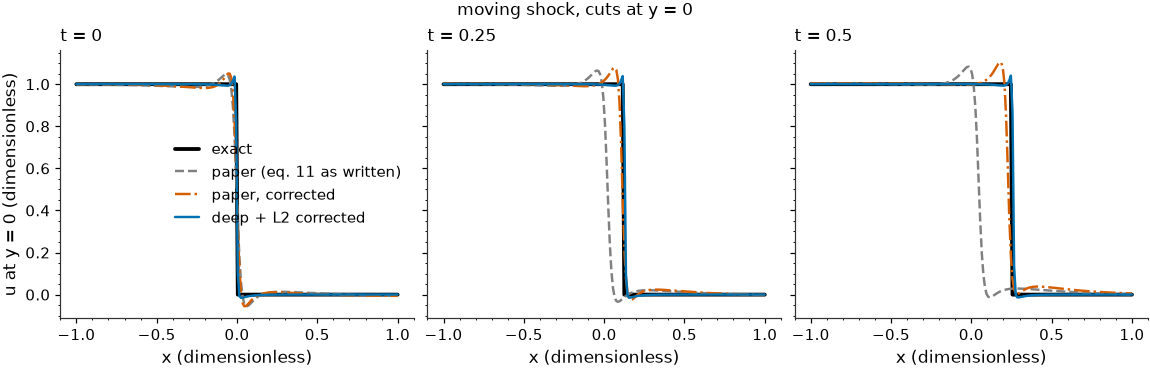

In [20]:
cut_styles = [(paper_name, "0.5", "--"), ("paper, corrected", "C1", "-."), (best_name, "C0", "-")]

times = [0.0, T / 2, T]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True, layout="constrained")
for ax, time_value in zip(axes, times):
    ax.plot(x_axis, exact_solution(x_axis, time_value), color="black", linewidth=2.5, label="exact")
    for name, color, line_style in cut_styles:
        u_cut = evaluate(results[name][0], x_axis, np.zeros_like(x_axis), np.full_like(x_axis, time_value))
        ax.plot(x_axis, u_cut, color=color, linestyle=line_style, label=name)
    ax.set_title(f"t = {time_value:.3g}")
    ax.set_xlabel("x (dimensionless)")
axes[0].set_ylabel("u at y = 0 (dimensionless)")
axes[0].legend()
fig.suptitle("moving shock, cuts at y = 0")
plt.show()

#### Figura 3: posición del choque en el tiempo

**Figura 3.** Posición del choque $x_s(t)$ (el primer $x$ donde $u$ baja de 0.5 en $y = 0$) de las
4 configuraciones. La exacta (negro) es la recta $x_s = t/2$. **Una línea plana es un choque que no
se mueve**; la pendiente es la velocidad del choque, y debería ser 1/2.

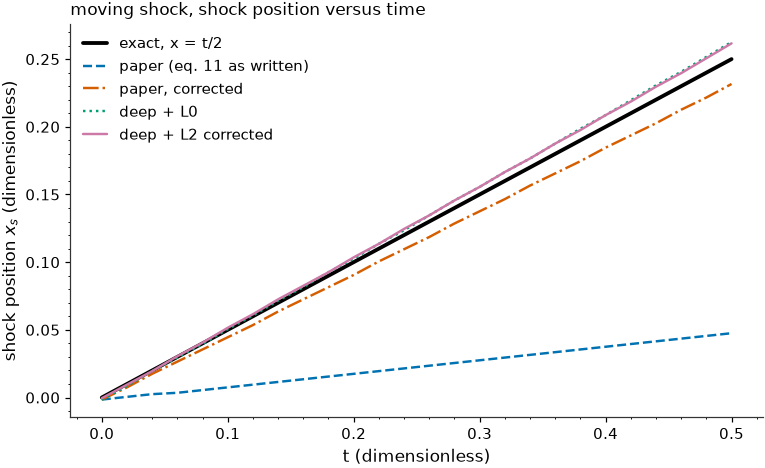

In [21]:
time_values = np.linspace(0.0, T, 26)
line_styles = {paper_name: "--", "paper, corrected": "-.", "deep + L0": ":", "deep + L2 corrected": "-"}

fig, ax = plt.subplots()
ax.plot(time_values, shock_speed * time_values, color="black", linewidth=2.5, label="exact, x = t/2")
for name, (network, history) in results.items():
    positions = [shock_position(network, time_value) for time_value in time_values]
    ax.plot(time_values, positions, linestyle=line_styles[name], label=name)
ax.set_xlabel("t (dimensionless)")
ax.set_ylabel(r"shock position $x_s$ (dimensionless)")
ax.set_title("moving shock, shock position versus time")
ax.legend()
plt.show()

#### Figura 4: dónde está el error

**Figura 4.** Error absoluto $|u - u_{\text{exacta}}|$ en $t = T$ del experimento del paper, del paper
corregido y de la mejor configuración, con **la misma escala de color para los tres**: un panel más
oscuro es de verdad un error menor. La línea blanca discontinua es el choque exacto $x = 0.25$.

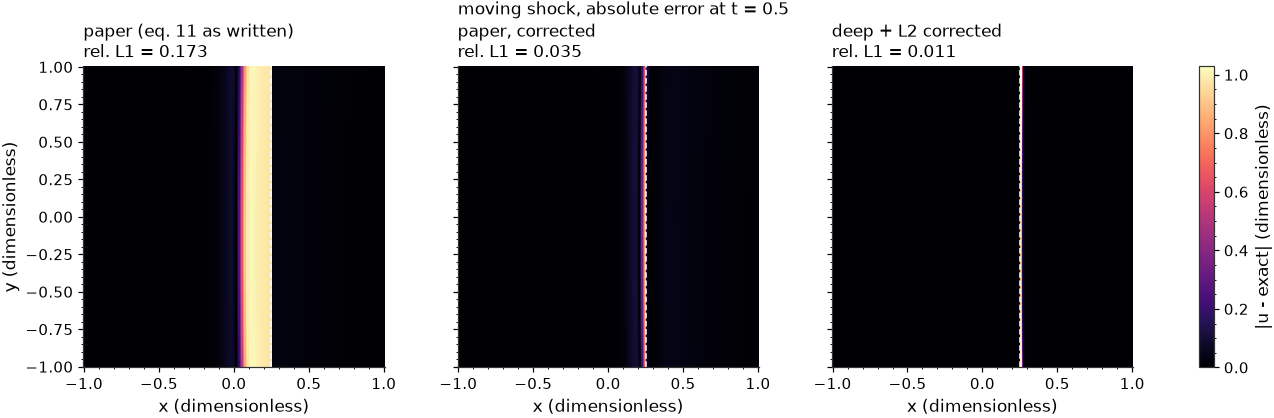

In [22]:
u_exact = exact_solution(X, T)
error_names = [paper_name, "paper, corrected", best_name]
error_maps = {name: np.abs(evaluate(results[name][0], X, Y, np.full_like(X, T)) - u_exact) for name in error_names}
error_max = max(error.max() for error in error_maps.values())

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), sharey=True, layout="constrained")
for ax, (name, error) in zip(axes, error_maps.items()):
    mesh = ax.pcolormesh(x_axis, y_axis, error, cmap="magma", vmin=0.0, vmax=error_max, shading="auto")
    ax.axvline(shock_speed * T, color="white", linestyle="--", linewidth=1.0)
    ax.set_title(f"{name}\nrel. L1 = {summary[name]['l1']:.3f}")
    ax.set_xlabel("x (dimensionless)")
    ax.set_aspect("equal")
axes[0].set_ylabel("y (dimensionless)")
fig.colorbar(mesh, ax=axes, label="|u - exact| (dimensionless)")
fig.suptitle(f"moving shock, absolute error at t = {T}")
plt.show()